# TMDB train + test combined, relabelled with the latest revenue

Kaggle never released revenues for `tmdb_test.csv`. Here both files are combined, every film is labelled with its latest worldwide gross from the IMDb dataset (`top_movies.feather`), and a new train / validation / test split is made.

1. Imports
2. Load the data
3. Tag the origin and combine
4. Look up the latest revenue
5. Clean budget and revenue
6. Compare the 2019 TMDB revenue with the latest revenue
7. Drop films without a latest revenue
8. Target and ROI
9. Train / validation / test split
10. Check the split
11. Save

## 1. Imports

In [1]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 60)
sns.set_theme(style="whitegrid", context="notebook")

## 2. Load the data

In [2]:
train = pd.read_csv("tmdb_train.csv")
test = pd.read_csv("tmdb_test.csv")
imdb = pd.read_feather("top_movies.feather", columns=["id", "title", "gross_worldwide"])

print(f"tmdb_train: {train.shape}")
print(f"tmdb_test:  {test.shape}")
print(f"top_movies: {imdb.shape}")
print("Columns only in train:", set(train.columns) - set(test.columns))

tmdb_train: (3000, 23)
tmdb_test:  (4398, 22)
top_movies: (63249, 3)
Columns only in train: {'revenue'}


## 3. Tag the origin and combine

`revenue` exists only in the train file. It is renamed `revenue_tmdb_2019` (the Kaggle snapshot) and will be empty for test films.

Release dates are `m/d/yy`; years `00`–`18` are 2000s and the rest 1900s (same rule as the EDA). One test film has no date.

In [3]:
train["orig_split"] = "train"
test["orig_split"] = "test"

df = pd.concat([train, test], ignore_index=True)
df = df.rename(columns={"revenue": "revenue_tmdb_2019"})

assert df["imdb_id"].is_unique, "duplicate imdb_id"

parts = df["release_date"].str.split("/", expand=True).astype(float)
yy = parts[2]
df["year"] = np.where(yy <= 18, 2000 + yy, 1900 + yy)
df.loc[yy.isna(), "year"] = np.nan
df["release_date"] = pd.to_datetime(dict(year=df["year"], month=parts[0], day=parts[1]), errors="coerce")

print(f"Combined: {df.shape}")
df["orig_split"].value_counts()

Combined: (7398, 25)


orig_split
test     4398
train    3000
Name: count, dtype: int64

## 4. Look up the latest revenue

The IMDb dataset stores worldwide gross as text such as `$27,399,597`. Only USD values are kept. The join key is the IMDb id (`imdb_id` in TMDB, `id` in the IMDb dataset).

In [4]:
def parse_usd(s):
    """'$27,399,597' -> 27399597.0; non-USD or missing -> NaN."""
    if not isinstance(s, str) or not s.startswith("$"):
        return np.nan
    digits = re.sub(r"[^\d]", "", s)
    return float(digits) if digits else np.nan


imdb["revenue_latest"] = imdb["gross_worldwide"].map(parse_usd)

df = df.merge(imdb[["id", "revenue_latest"]], left_on="imdb_id", right_on="id",
              how="left", suffixes=("", "_imdb")).drop(columns="id_imdb")
df["revenue_source"] = np.where(df["revenue_latest"].notna(), "imdb_worldwide_gross", None)

df.groupby("orig_split")["revenue_latest"].agg(films="size", with_latest_revenue="count")

,films,with_latest_revenue
orig_split,,
test,4398,3906
train,3000,2652


## 5. Clean budget and revenue

Same rule as the EDA: amounts below **$10,000** are errors or unknown (TMDB uses 0 for unknown budgets), so they become `NaN`.

In [5]:
MIN_AMOUNT = 10_000

for c in ["budget", "revenue_tmdb_2019", "revenue_latest"]:
    df[c] = df[c].where(df[c] >= MIN_AMOUNT)

df.groupby("orig_split")[["budget", "revenue_tmdb_2019", "revenue_latest"]].count()

,budget,revenue_tmdb_2019,revenue_latest
orig_split,,,
test,3152,0,3845
train,2165,2908,2604


## 6. Compare the 2019 TMDB revenue with the latest revenue

Only original train films have both. `ratio = revenue_latest / revenue_tmdb_2019`; a ratio above 2 or below 0.5 is flagged.

In [6]:
df["revenue_ratio"] = df["revenue_latest"] / df["revenue_tmdb_2019"]
df["revenue_mismatch"] = (df["revenue_ratio"] > 2) | (df["revenue_ratio"] < 0.5)

both = df["revenue_ratio"].notna()
log_ratio = np.log10(df.loc[both, "revenue_ratio"])
print(f"Films with both revenues: {both.sum():,}")
print(f"Median ratio:            {df.loc[both, 'revenue_ratio'].median():.3f}")
print(f"Within 10%:              {(log_ratio.abs() < np.log10(1.1)).mean():.1%}")
print(f"Within a factor of 2:    {(log_ratio.abs() < np.log10(2)).mean():.1%}")
print(f"Flagged (> 2x apart):    {df['revenue_mismatch'].sum():,}")

Films with both revenues: 2,556
Median ratio:            1.000
Within 10%:              73.9%
Within a factor of 2:    87.6%
Flagged (> 2x apart):    318


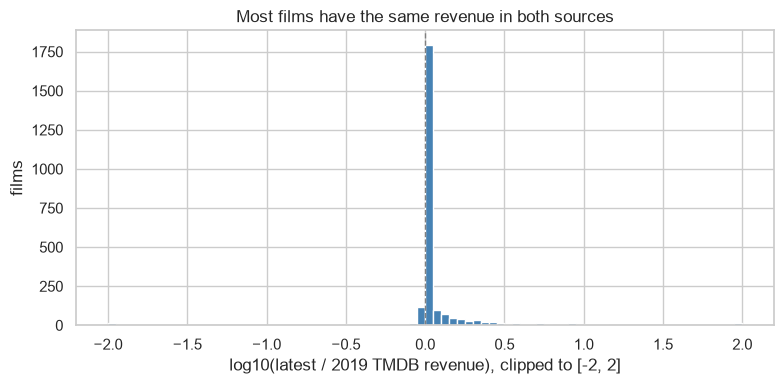

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(log_ratio.clip(-2, 2), bins=80, color="steelblue")
ax.axvline(0, color="gray", ls="--", lw=1)
ax.set_xlabel("log10(latest / 2019 TMDB revenue), clipped to [-2, 2]")
ax.set_ylabel("films")
ax.set_title("Most films have the same revenue in both sources")
plt.tight_layout()

Where they disagree, the direction depends on the era:

- **Latest much higher** (mostly films from 2000 on): the 2019 TMDB value was small and incomplete; the IMDb worldwide gross is more complete.
- **Latest much lower** (mostly films before 1980, and some Indian films): IMDb often records only a re-release or partial gross, so the **IMDb figure is too low**. Test films have no 2019 value, so this cannot be detected for them.

In [8]:
era3 = pd.cut(df["year"], [1900, 1979, 1999, 2020], labels=["before 1980", "1980-1999", "2000+"])
direction = np.select([df["revenue_ratio"] > 2, df["revenue_ratio"] < 0.5], ["latest much higher", "latest much lower"], "agree")
pd.crosstab(era3[both], direction[both], margins=True)

col_0,agree,latest much higher,latest much lower,All
year,,,,
before 1980,88,3,35,126
1980-1999,805,19,21,845
2000+,1345,216,24,1585
All,2238,238,80,2556


The largest disagreements:

In [9]:
df.loc[both, ["title", "release_date", "revenue_tmdb_2019", "revenue_latest", "revenue_ratio"]] \
  .assign(abs_log=log_ratio.abs()).sort_values("abs_log", ascending=False).drop(columns="abs_log").head(15)

,title,release_date,revenue_tmdb_2019,revenue_latest,revenue_ratio
614,The Guns of Navarone,1961-04-27,28900000.0,20616.0,0.000713
1686,Red River,1948-08-26,9012000.0,14462.0,0.001605
606,The Taking of Tiger Mountain,2014-12-24,228984.0,141654055.0,618.619882
688,The Devil's Violinist,2013-01-30,11294.0,4069418.0,360.316805
685,Bad Day at Black Rock,1955-01-07,3788000.0,10813.0,0.002855
505,Special Forces,2011-11-02,10759.0,3424648.0,318.305419
758,Lolo,2015-09-03,24134.0,7663798.0,317.551918
736,Quo Vadis,1951-11-08,30000000.0,101486.0,0.003383
1421,Tomorrow,2015-12-02,43471.0,11291395.0,259.745462
992,Top Hat,1935-09-06,3202000.0,13592.0,0.004245


## 7. Drop films without a latest revenue

In [10]:
before = df["orig_split"].value_counts()
df = df[df["revenue_latest"].notna()].reset_index(drop=True)
after = df["orig_split"].value_counts()

pd.DataFrame({"before": before, "after": after, "dropped": before - after})

,before,after,dropped
orig_split,,,
test,4398,3845,553
train,3000,2604,396


## 8. Target and ROI

The target for every film is `revenue_latest`. `revenue_tmdb_2019` is kept for reference only.

In [11]:
df["revenue"] = df["revenue_latest"]
df["roi"] = df["revenue"] / df["budget"]

print(f"Films: {len(df):,}   with ROI: {df['roi'].notna().sum():,}")
print(f"Years: {df['year'].min():.0f}–{df['year'].max():.0f}")

Films: 6,449   with ROI: 4,755
Years: 1921–2017


## 9. Train / validation / test split

70 / 15 / 15, stratified by release era so each part spans the same years. Decades before 1970 have few films and are merged into one group. `orig_split` is ignored here.

In [12]:
SEED = 42

decade = (df["year"] // 10 * 10)
df["era"] = np.where(decade < 1970, "pre-1970", decade.astype("Int64").astype(str))
df.loc[df["year"].isna(), "era"] = "unknown"
df["era"] = df["era"].replace({"unknown": df["era"].mode()[0]})   # 1 film with no date

idx_train, idx_rest = train_test_split(df.index, test_size=0.30, stratify=df["era"], random_state=SEED)
idx_val, idx_test = train_test_split(idx_rest, test_size=0.50, stratify=df.loc[idx_rest, "era"], random_state=SEED)

df["split"] = "train"
df.loc[idx_val, "split"] = "val"
df.loc[idx_test, "split"] = "test"

df["split"].value_counts().reindex(["train", "val", "test"])

split
train    4514
val       967
test      968
Name: count, dtype: int64

## 10. Check the split

In [13]:
check = df.groupby("split").agg(
    films=("imdb_id", "size"),
    median_year=("year", "median"),
    median_revenue_musd=("revenue", lambda s: s.median() / 1e6),
    budget_known=("budget", lambda s: s.notna().mean()),
    median_roi=("roi", "median"),
    from_orig_test=("orig_split", lambda s: (s == "test").mean()),
).reindex(["train", "val", "test"])
check.round(2)

,films,median_year,median_revenue_musd,budget_known,median_roi,from_orig_test
split,,,,,,
train,4514,2004.0,23.29,0.75,2.12,0.59
val,967,2004.0,21.35,0.71,1.98,0.63
test,968,2004.0,20.23,0.71,1.97,0.57


In [14]:
pd.crosstab(df["era"], df["split"]).reindex(columns=["train", "val", "test"])

split,train,val,test
era,,,
1970,127,27,27
1980,585,125,126
1990,883,189,189
2000,1430,306,307
2010,1371,294,294
pre-1970,118,26,25


## 11. Save

One file with every film, its new `split`, the target `revenue`, and the original columns. JSON-like columns stay as text, to be parsed as in the EDA.

In [15]:
df = df.drop(columns=["era"])
df.to_csv("tmdb_combined.csv", index=False)
print(f"Saved tmdb_combined.csv: {df.shape}")

Saved tmdb_combined.csv: (6449, 32)


In [16]:
df.head()

,id,belongs_to_collection,budget,genres,homepage,imdb_id,original_language,original_title,overview,popularity,poster_path,production_companies,production_countries,release_date,runtime,spoken_languages,status,tagline,title,Keywords,cast,crew,revenue_tmdb_2019,orig_split,year,revenue_latest,revenue_source,revenue_ratio,revenue_mismatch,revenue,roi,split
0,1,"[{'id': 313576, 'name': 'Hot Tub Time Machine Collection...",14000000.0,"[{'id': 35, 'name': 'Comedy'}]",NaN,tt2637294,en,Hot Tub Time Machine 2,"When Lou, who has become the ""father of the Internet,"" i...",6.575393,/tQtWuwvMf0hCc2QR2tkolwl7c3c.jpg,"[{'name': 'Paramount Pictures', 'id': 4}, {'name': 'Unit...","[{'iso_3166_1': 'US', 'name': 'United States of America'}]",2015-02-20,93.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,The Laws of Space and Time are About to be Violated.,Hot Tub Time Machine 2,"[{'id': 4379, 'name': 'time travel'}, {'id': 9663, 'name...","[{'cast_id': 4, 'character': 'Lou', 'credit_id': '52fe4e...","[{'credit_id': '59ac067c92514107af02c8c8', 'department':...",12314651.0,train,2015.0,13081651.0,imdb_worldwide_gross,1.062284,False,13081651.0,0.934404,train
1,2,"[{'id': 107674, 'name': 'The Princess Diaries Collection...",40000000.0,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'name': 'Drama...",NaN,tt0368933,en,The Princess Diaries 2: Royal Engagement,Mia Thermopolis is now a college graduate and on her way...,8.248895,/w9Z7A0GHEhIp7etpj0vyKOeU1Wx.jpg,"[{'name': 'Walt Disney Pictures', 'id': 2}]","[{'iso_3166_1': 'US', 'name': 'United States of America'}]",2004-08-06,113.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,It can take a lifetime to find true love; she's got 30 d...,The Princess Diaries 2: Royal Engagement,"[{'id': 2505, 'name': 'coronation'}, {'id': 4263, 'name'...","[{'cast_id': 1, 'character': 'Mia Thermopolis', 'credit_...","[{'credit_id': '52fe43fe9251416c7502563d', 'department':...",95149435.0,train,2004.0,134734481.0,imdb_worldwide_gross,1.416030,False,134734481.0,3.368362,train
2,3,NaN,3300000.0,"[{'id': 18, 'name': 'Drama'}]",http://sonyclassics.com/whiplash/,tt2582802,en,Whiplash,"Under the direction of a ruthless instructor, a talented...",64.299990,/lIv1QinFqz4dlp5U4lQ6HaiskOZ.jpg,"[{'name': 'Bold Films', 'id': 2266}, {'name': 'Blumhouse...","[{'iso_3166_1': 'US', 'name': 'United States of America'}]",2014-10-10,105.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,The road to greatness can take you to the edge.,Whiplash,"[{'id': 1416, 'name': 'jazz'}, {'id': 1523, 'name': 'obs...","[{'cast_id': 5, 'character': 'Andrew Neimann', 'credit_i...","[{'credit_id': '54d5356ec3a3683ba0000039', 'department':...",13092000.0,train,2014.0,50360880.0,imdb_worldwide_gross,3.846691,True,50360880.0,15.260873,train
3,6,NaN,8000000.0,"[{'id': 16, 'name': 'Animation'}, {'id': 12, 'name': 'Ad...",NaN,tt0093743,en,Pinocchio and the Emperor of the Night,"Pinocchio and his friends, a glow worm and a marionette,...",0.743274,/6IDqA1D2NBIVhzEEaMMRL28iBrq.jpg,NaN,NaN,1987-08-06,83.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Pinocchio and the Emperor of the Night,NaN,"[{'cast_id': 6, 'character': 'Pinocchio (voice)', 'credi...","[{'credit_id': '52fe46f49251416c9106558b', 'department':...",3261638.0,train,1987.0,3261638.0,imdb_worldwide_gross,1.000000,False,3261638.0,0.407705,train
4,7,NaN,14000000.0,"[{'id': 27, 'name': 'Horror'}, {'id': 53, 'name': 'Thril...",http://www.thepossessionmovie.com/,tt0431021,en,The Possession,"A young girl buys an antique box at a yard sale, unaware...",7.286477,/4QjzFuaZmB4btGnLwAgdp23BzIU.jpg,"[{'name': 'Ghost House Pictures', 'id': 768}, {'name': '...","[{'iso_3166_1': 'US', 'name': 'United States of America'...",2012-08-30,92.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Fear The Demon That Doesn't Fear God,The Possession,NaN,"[{'cast_id': 23, 'character': 'Clyde', 'credit_id': '52f...","[{'credit_id': '52fe4981c3a368484e12ee29', 'department':...",85446075.0,train,2012.0,85446075.0